# PCD ASSIGNMENT 3
Muhammad Fathan Romiza
25/560518/PA/23623


# 0.Import Library


In [1]:
import requests
import re
import numpy as np
from io import BytesIO
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display

# 1.1 TO GRAYSCALE


In [2]:
def to_gray(img):
    arr = np.array(img)
    if arr.ndim == 2:
        return arr.astype(np.uint8)
    if arr.shape[2] == 4:
        arr = arr[:, :, :3]
    gray = (0.299 * arr[:, :, 0] + 0.587 * arr[:, :, 1] + 0.114 * arr[:, :, 2])
    return gray.astype(np.uint8)

# 1.2 GAUSSIAN BLUR (MANUAL CONVOLUTION)


In [3]:
def gaussian_kernel(size=5, sigma=1):
    ax = np.linspace(-(size // 2), size // 2, size)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2.0 * sigma**2))
    return kernel / np.sum(kernel)

def convolve(image, kernel):
    k = kernel.shape[0] // 2
    padded = np.pad(image, pad_width=k, mode='edge')
    output = np.zeros_like(image, dtype=np.float32)
    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            region = padded[i:i + kernel.shape[0], j:j + kernel.shape[1]]
            output[i, j] = np.sum(region * kernel)
    return output.astype(np.uint8)

def gaussian_blur(img, size=5, sigma=1):
    gray = to_gray(img)
    return convolve(gray, gaussian_kernel(size, sigma))

# 2.1 OTSU THRESHOLDING


In [4]:
def otsu_threshold(image):
    hist, _ = np.histogram(image.ravel(), bins=256, range=(0, 255))
    total = image.size
    sum_total = np.dot(np.arange(256), hist)
    sumB, wB = 0.0, 0.0
    current_max, threshold = 0.0, 0

    for t in range(256):
        wB += hist[t]
        if wB == 0:
            continue
        wF = total - wB
        if wF == 0:
            break
        sumB += t * hist[t]
        mB = sumB / wB
        mF = (sum_total - sumB) / wF
        between = wB * wF * (mB - mF) ** 2
        if between > current_max:
            current_max = between
            threshold = t
    return threshold

def otsu_segment(gray):
    T = otsu_threshold(gray)
    binary = np.zeros_like(gray)
    binary[gray >= T] = 255
    return binary, T

# 3.1 STRUCTURING ELEMENT


In [5]:
def struct_elem():
    return np.ones((3, 3), dtype=int)

# 3.2 EROSION


In [6]:
def erosion(binary_image):
    se = struct_elem()
    rows, cols = binary_image.shape
    eroded = np.zeros_like(binary_image)
    for i in range(1, rows - 1):
        for j in range(1, cols - 1):
            region = binary_image[i - 1:i + 2, j - 1:j + 2]
            if np.all(region[se == 1] == 1):
                eroded[i, j] = 1
    return eroded

# 3.3 DILATION


In [7]:
def dilation(binary_image):
    se = struct_elem()
    rows, cols = binary_image.shape
    dilated = np.zeros_like(binary_image)
    for i in range(1, rows - 1):
        for j in range(1, cols - 1):
            region = binary_image[i - 1:i + 2, j - 1:j + 2]
            if np.any(region[se == 1] == 1):
                dilated[i, j] = 1
    return dilated

# 3.4 OPENING


In [8]:
def opening(binary_image):
    return dilation(erosion(binary_image))

# 3.5 CLOSING


In [9]:
def closing(binary_image):
    return erosion(dilation(binary_image))

# 4. MAIN FUNCTION
Main function for managing eksperiment


In [10]:
def display_results(img, results, titles):
    plt.figure(figsize=(15, 5))

    images = [img] + results
    titles = ["Original"] + titles

    for i, (image, title) in enumerate(zip(images, titles), 1):
        plt.subplot(1, len(images), i)
        image_np = np.array(image)
        if image_np.ndim == 2:
            plt.imshow(image_np, cmap="gray")
        else:
            plt.imshow(image_np)
        plt.title(title)
        plt.axis("off")

    plt.tight_layout()
    plt.show()

def eksperiment(image):
    gray = to_gray(image)
    blurred = gaussian_blur(image, size=5, sigma=1)

    # Segmentasi: Otsu TANPA morfologi
    binary, T = otsu_segment(blurred)
    print("Nilai ambang Otsu =", T)

    display_results(
        gray,
        [binary],
        ["Otsu (tanpa morfologi)"]
    )

    # Segmentasi: Otsu + morfologi
    bin01 = (binary > 0).astype(int)

    morph_results = [
        erosion(bin01)  * 255,
        dilation(bin01) * 255,
        opening(bin01)  * 255,
        closing(bin01)  * 255,
    ]

    display_results(
        binary,
        morph_results,
        ["Erosion", "Dilation", "Opening", "Closing"]
    )

# 5.0 Image Load, Function Call


Nilai ambang Otsu = 101


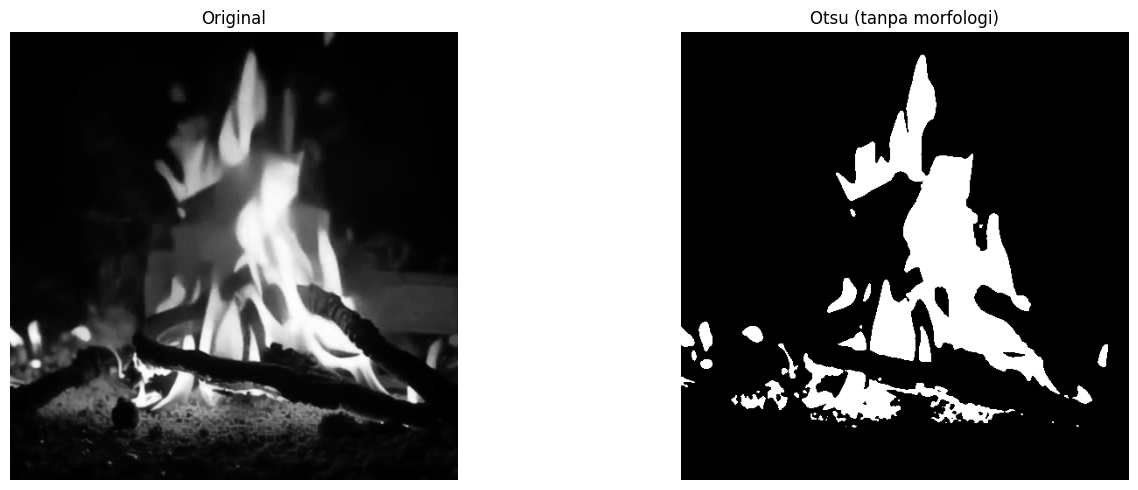

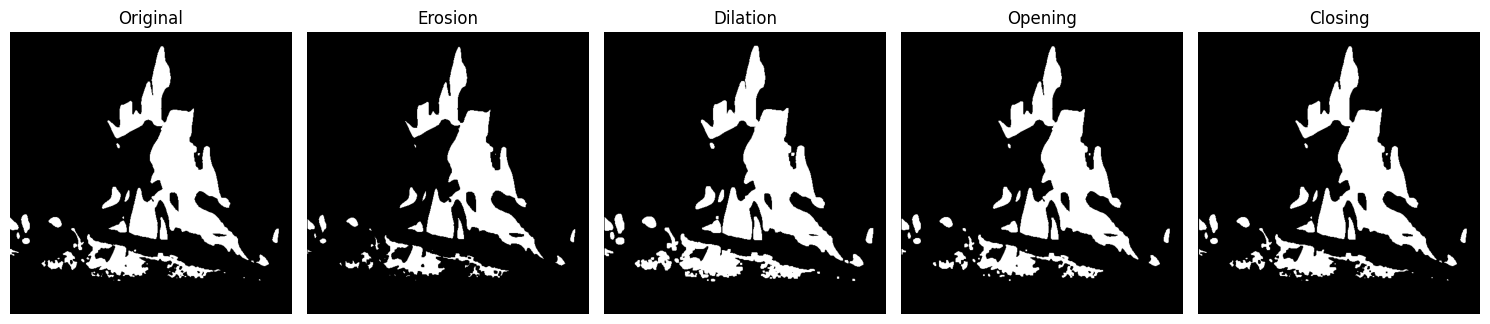

Nilai ambang Otsu = 181


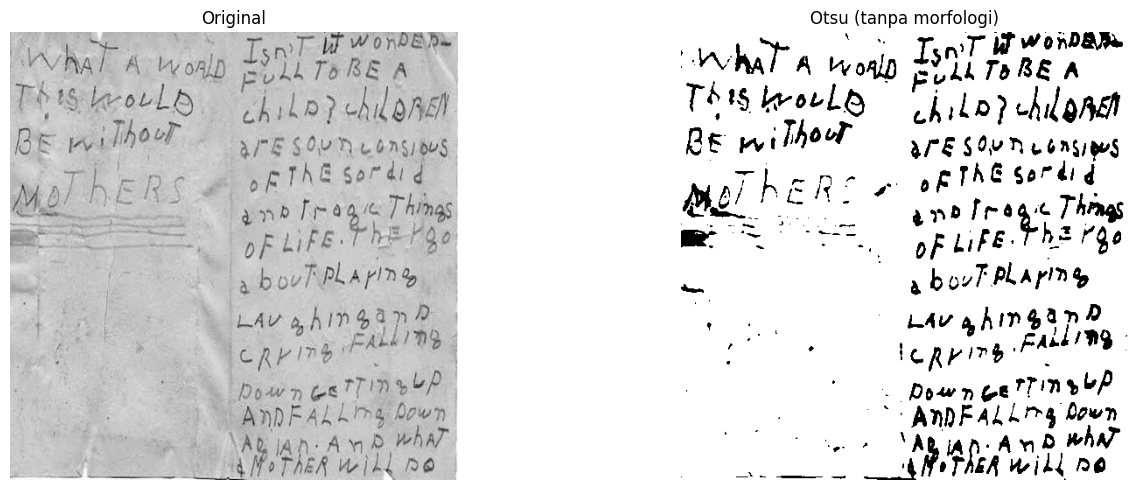

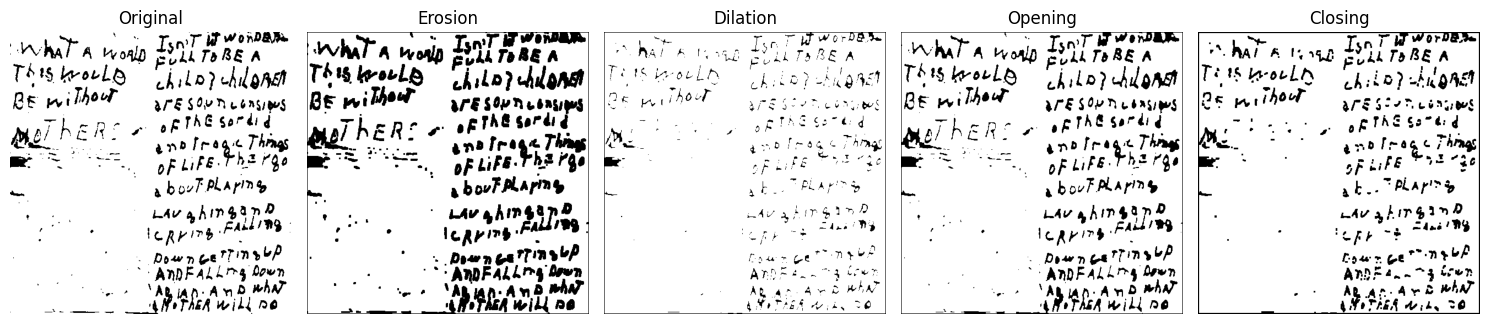

Nilai ambang Otsu = 108


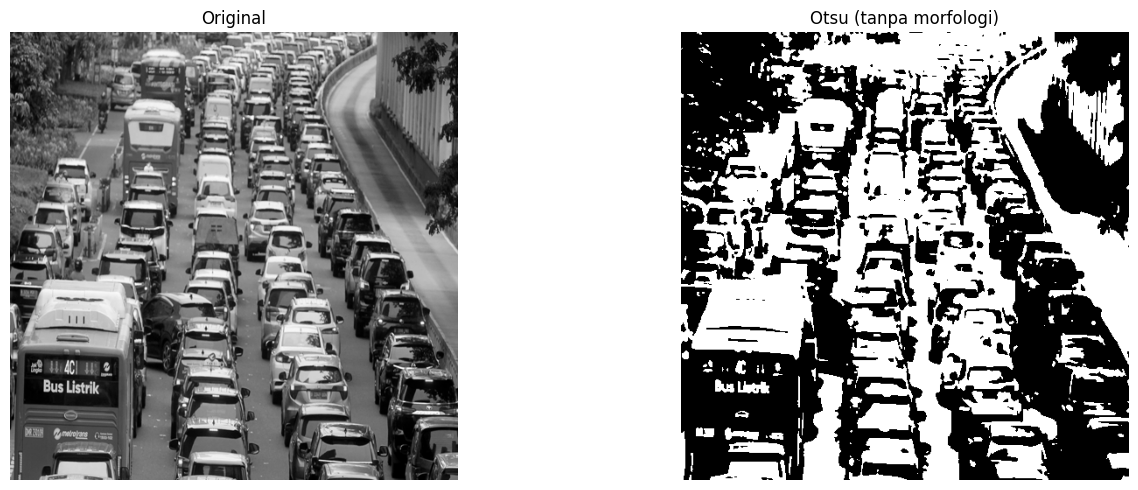

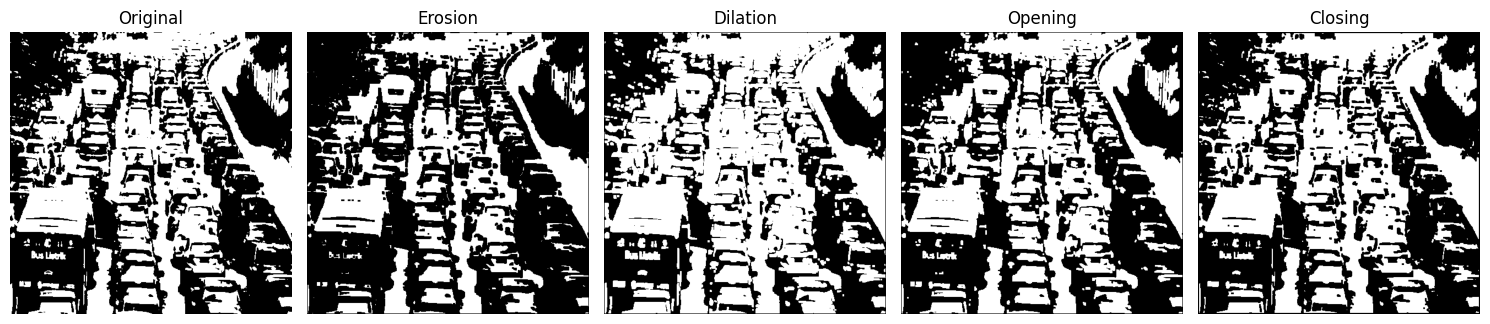

Nilai ambang Otsu = 88


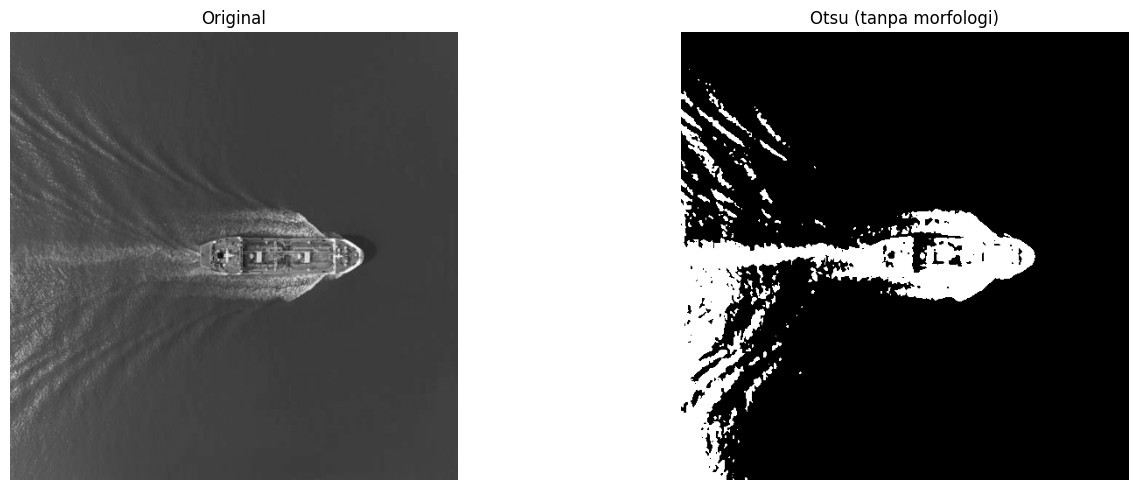

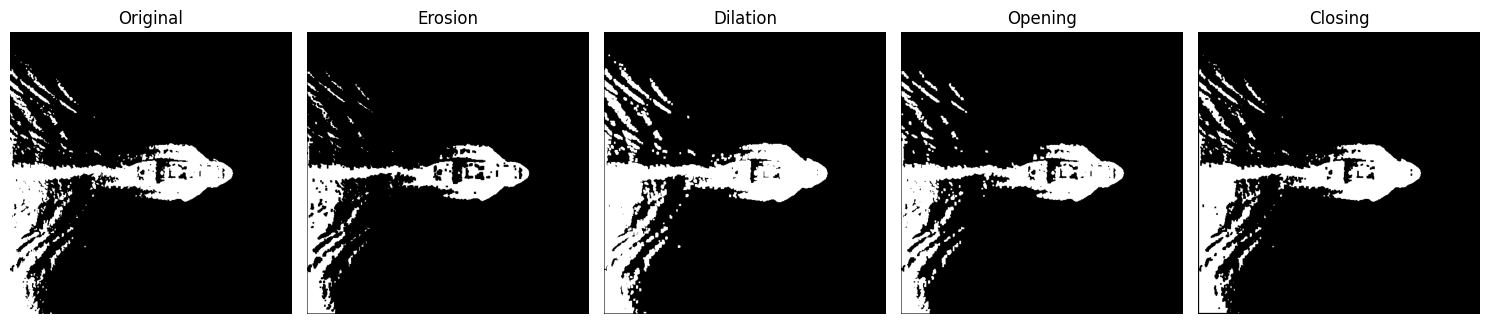

Nilai ambang Otsu = 94


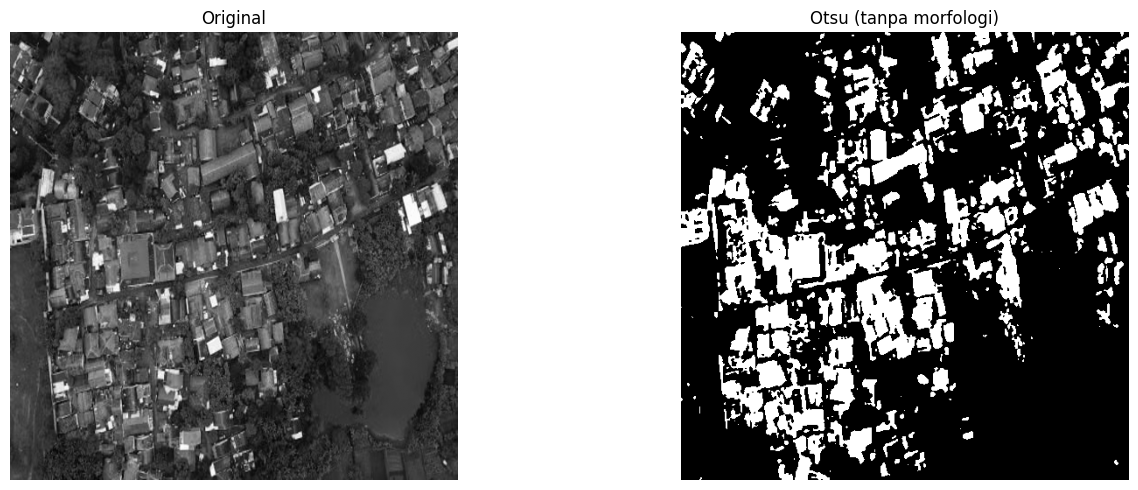

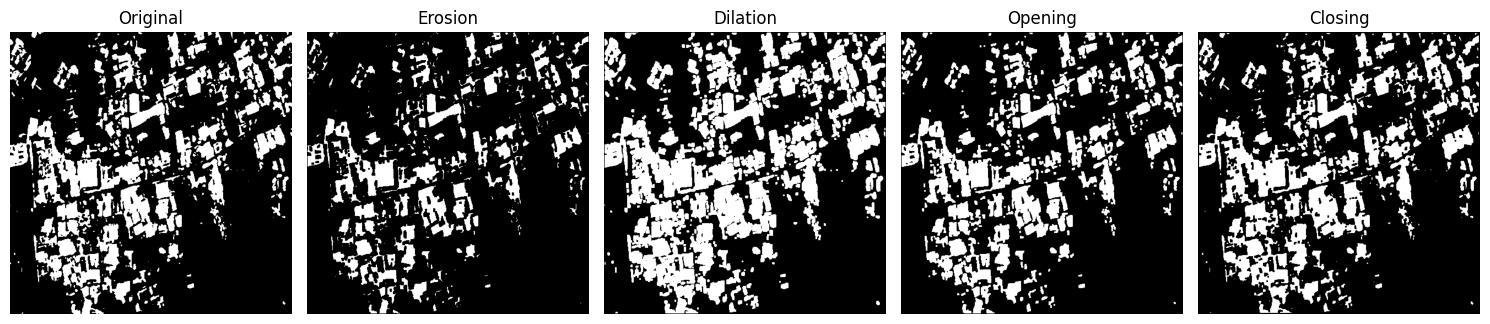

Nilai ambang Otsu = 4


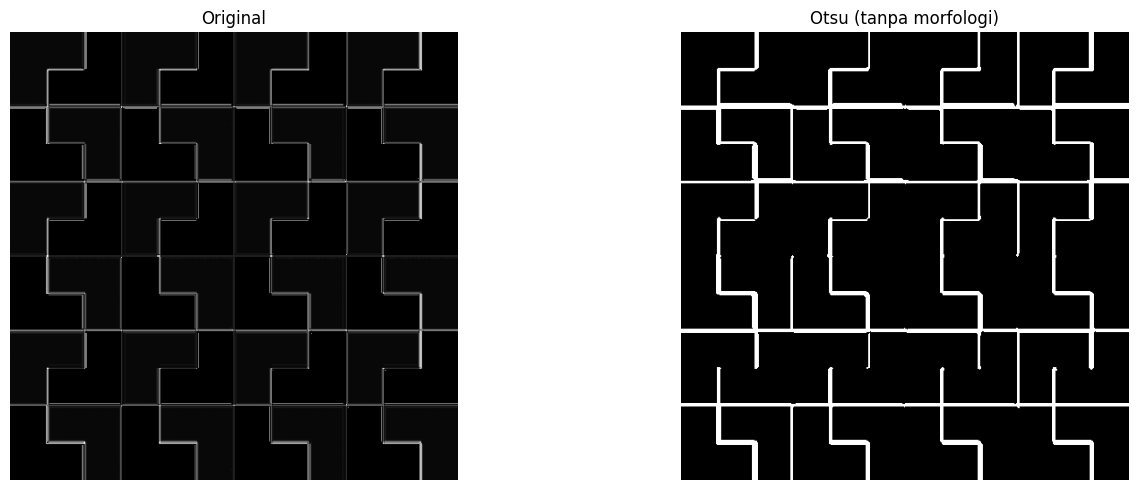

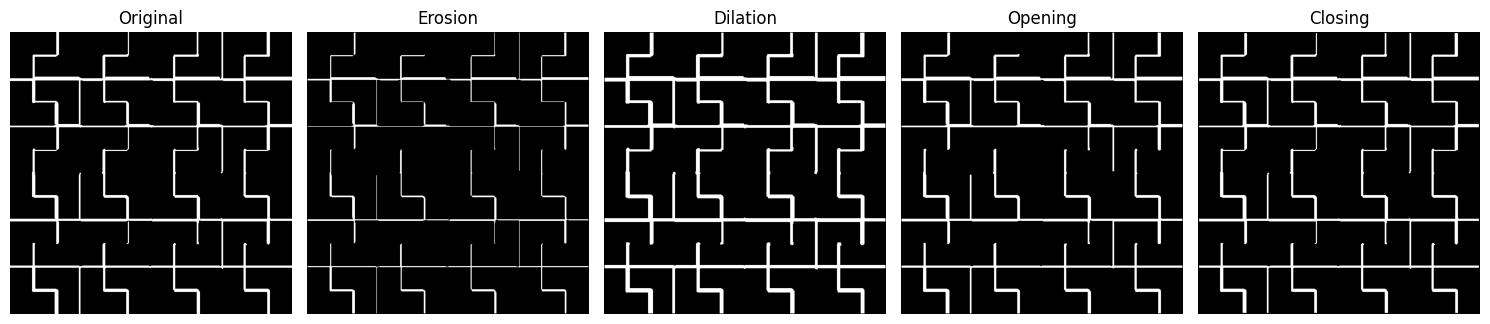

In [11]:
images = [
    'https://drive.google.com/file/d/1O3tAm6GSiBAD0KbUPxodTs-7DYLlh_Dp/view?usp=sharing',
    'https://drive.google.com/file/d/1nIcILIRO2IQfhRHch7mzxtvIN8DZX-C-/view?usp=sharing',
    'https://drive.google.com/file/d/15QvrX1cvrM1wZcqXr__LU8dUviTokP64/view?usp=sharing',
    'https://drive.google.com/file/d/1n9m4xqukhUCfizUBKj7qsyzAqAzpEXd8/view?usp=sharing',
    'https://drive.google.com/file/d/1PBpUQryyoVp_LegWweb7UV52ZjdAiQ_v/view?usp=sharing',
    'https://drive.google.com/file/d/1Oi5UksXscCQFZrNphnlEhJ_QByqDzCIc/view?usp=sharing',
]


def resize(src, size=(512, 512)):
    file_id = re.search(r"/d/([^/]+)", src).group(1)

    download_url = f"https://drive.google.com/uc?export=download&id={file_id}"

    response = requests.get(download_url)
    response.raise_for_status()

    image = Image.open(BytesIO(response.content))
    image = image.resize(size)

    return image

for src in images:
    image = resize(src)
    eksperiment(image)